# 실습 목표
- -> 선형 모델을 활용해서 각 특성마다 알맞은 가중치를 매겨보자
- 가중치(기울기) : 해당 값(x)이 늘어나면, y값이 얼마나 변동하는지에 대한 값
- 공부시간 : 성적 = 공부시간 X 가중치 () - > 양의 가중치 (y랑 x의 값이 정비례)
- 노는시간 : 성적 = 노는시간 X 가중치 -> 음의 가중치(y랑 x의 값이 반비례)

In [1]:
# 라이브러리 불러오기
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# 데이터 불러오기(변수명 : data), index_col = 인덱스할 컬럼
data = pd.read_csv('data/insurance.csv')

C:\Users\smart\AppData\Local\Temp\ipykernel_16124\2797604763.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([ data[data['region'] == 'southwest']['charges'],


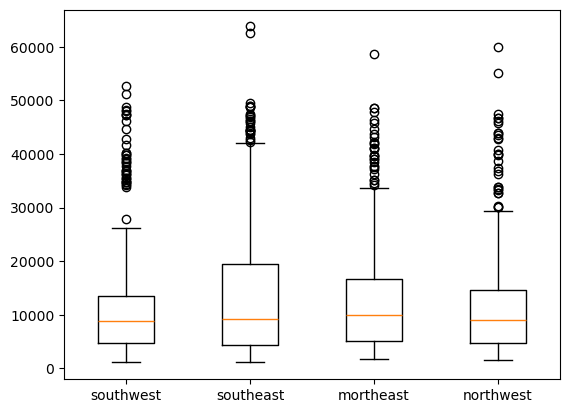

In [9]:
# 의료비를 예측하는데 불필요한 특성까지 학습 시키면
# 모델이 잘못된 해석을 하는 경우가 발생 -> 과대적합
# -> EDA(탐색적 데이터 분석)을 통해 걸러냄!

data.head()

# region(사는지역)이 의료비 데이터를 예측하는데 도움이 되는지 확인
# 지역별, 의료비 데이터의 분포도 시각화

data['region'].unique() # 4종류의 문자데이터로 구성

# boxplot
from matplotlib import pyplot as plt

# 지역별로 의료비의 분포를 확인
# data[data['region'] == 'southwest'] -> 사는 지역이 southwest인 데이터만 필터링
plt.boxplot([ data[data['region'] == 'southwest']['charges'],
              data[data['region'] == 'southeast']['charges'],
              data[data['region'] == 'northeast']['charges'],
              data[data['region'] == 'northwest']['charges']  ],
              labels = ['southwest', 'southeast', 'mortheast', 'northwest']
               
                 )
plt.show()

# 이상치 : 정상적인 데이터 분포에서 벗어난 데이터
# IQR이 이상치 판단의 절대적인 기준은 X, 데이터의 특성에 따라서 전처리 고려


age : 나이
sex : 성별
bmi : 체질량 지수
children : 부양 가족 수
smoker : 흡연 여부
region : 사는 지역
charges : 개인 의료비(답데이터)

In [11]:
# 선형회귀 모델을 활용해서 모델링
# -> 문자데이터를 숫자데이터로 바꿔주는 인코딩!


one_data = pd.get_dummies(data)


In [14]:
# 특성 데이터, 정답 데이터 분리
x = one_data.drop('charges', axis = 1)
y = one_data['charges']

# train. test 데이터 분리( 7 : 3)
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state = 7)

In [16]:
print('x_train : ', x_train.shape)
print('x_test : ', x_test.shape)
print('y_train : ', y_train.shape)
print('y_test : ', y_test.shape)

x_train :  (936, 11)
x_test :  (402, 11)
y_train :  (936,)
y_test :  (402,)


In [21]:
from sklearn.linear_model import LinearRegression


# 좋은 선형모델은, 오차가 적게 예측하는 모델이다!
model = LinearRegression()

# 학습
model.fit(x_train, y_train)

# y = wx + b
# w(가중치), b(절편)값을 확인
model.coef_

# DataFrame으로 만들어서 가중치 확인
# 의료비 = age * 253.22 + bmi * 365.311 + ... + 절편(b)
pd.DataFrame(model.coef_,
             index = x_train.columns)

# 절편 확인
# model.intercept_

np.float64(-1373.4735243952236)

In [22]:
# 모델의 성능 확인
# -> score 

model.score(x_test, y_test)

0.7516810217281062

In [26]:
# 오차를 계산하는 방법
# 1. MSE(Mean Squared Error) : 오차를 제곱해서 평균냄
# 실제 상전 : 230,000원
# 예측 [210,000원 / 220,000원]
(((230000 - 210000) ** 2) + ((230000-220000) **2)) / 2

# 2. RMSE(Root Mean Squeared Error)
# 단위가 너무 커지는 것을 방지
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score

# 예측값과 오차값 비교해서 mse 계산
pre = model.predict(x_test)

mse = mean_squared_error(y_test, pre)
print('mse 값 :', mse)

mse 값 : 36313025.727236286


In [ ]:
# MSE라는 오차가 작은 W(가중치)와 b(편향)값을 찾는 것이 목적